<a href="https://colab.research.google.com/github/eiyu18/MachineLearning/blob/main/JS08/JS08_Lab03.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import HDBSCAN
from sklearn.datasets import make_blobs

In [6]:
def plot(X, labels, probabilities=None, parameters=None, ground_truth=False, ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(10, 4))

    labels = labels if labels is not None else np.ones(X.shape[0])
    probabilities = probabilities if probabilities is not None else np.ones(X.shape[0])

    unique_labels = set(labels)
    colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]

    proba_map = {idx: probabilities[idx] for idx in range(len(labels))}

    for k, col in zip(unique_labels, colors):
        if k == -1:
            col = [0, 0, 0, 1]

        class_index = (labels == k).nonzero()[0]

        for ci in class_index:
            ax.plot(
                X[ci, 0],
                X[ci, 1],
                'x' if k == -1 else 'o',
                markerfacecolor=tuple(col),
                markeredgecolor='k',
                markersize=4 if k == -1 else 1 + 5 * proba_map[ci]
            )

    n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
    preamble = 'True' if ground_truth else 'Estimated'
    title = f'{preamble} number of clusters: {n_clusters_}'

    if parameters is not None:
        parameters_str = ', '.join(f'{k}={v}' for k, v in parameters.items())
        title += f' | {parameters_str}'

    ax.set_title(title)
    plt.tight_layout()

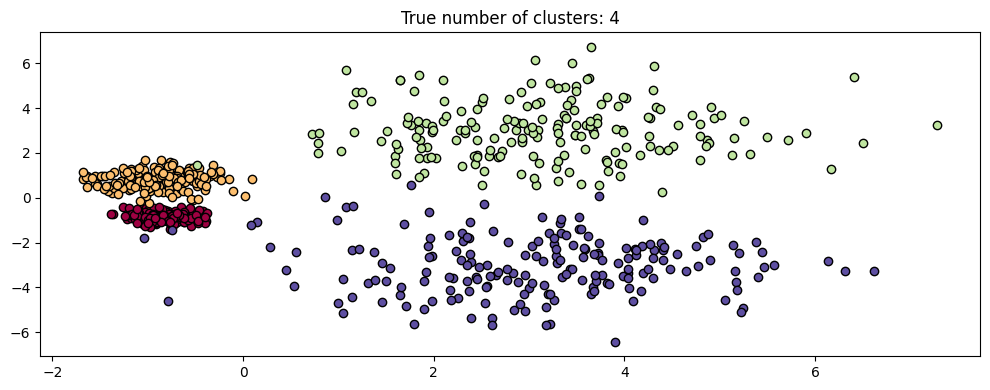

In [7]:
centers = [[-0.85, -0.85], [-0.85, 0.85], [3, 3], [3, -3]]

X, labels_true = make_blobs(
    n_samples=750, centers=centers, cluster_std=[0.2, 0.35, 1.35, 1.35], random_state=0
)

plot(X, labels=labels_true, ground_truth=True)
plt.show()

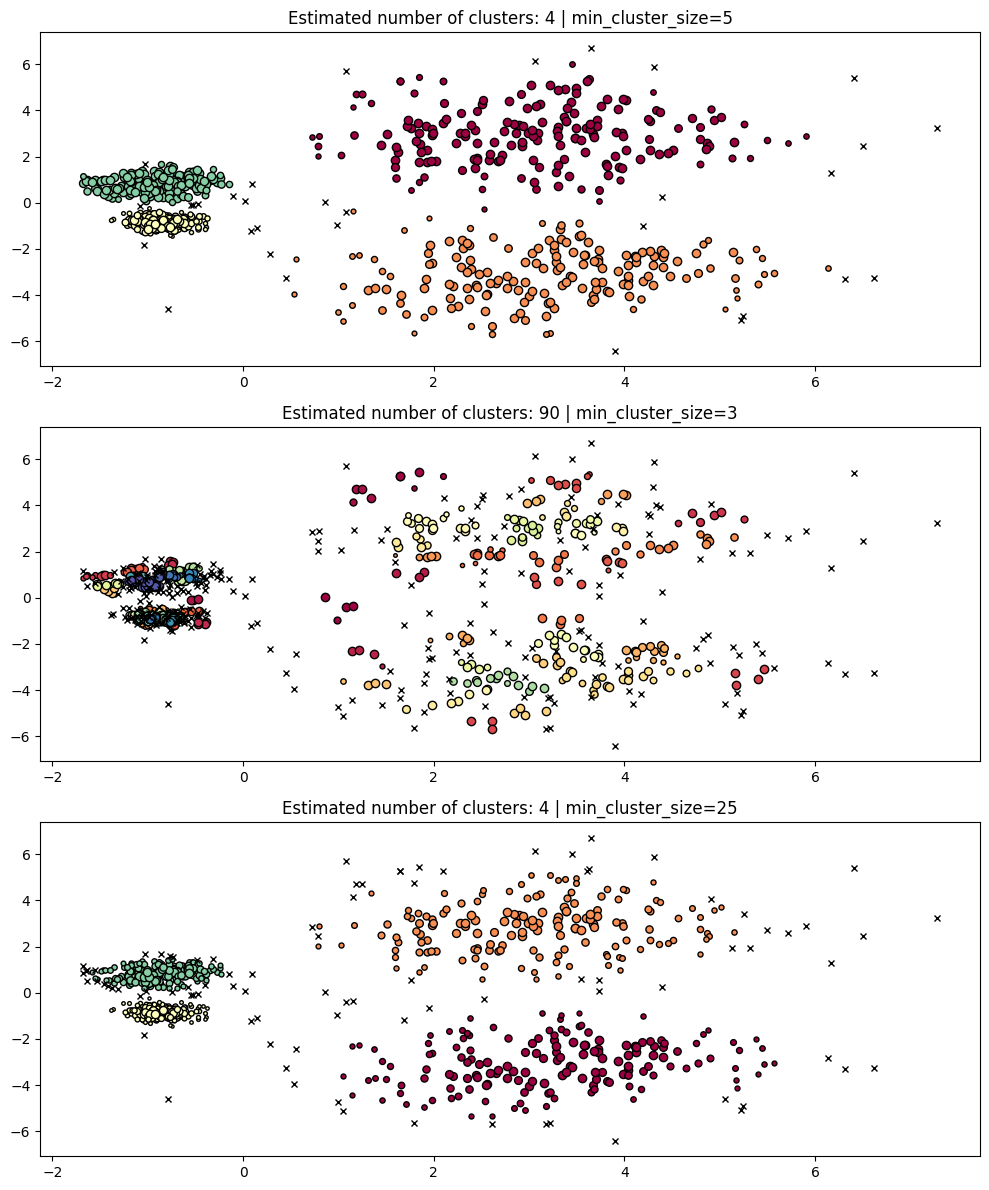

In [8]:
PARAM = ({'min_cluster_size': 5}, {'min_cluster_size': 3}, {'min_cluster_size': 25})

fig, axes = plt.subplots(len(PARAM), 1, figsize=(10, 12))

for i, param in enumerate(PARAM):
    hdb = HDBSCAN(**param).fit(X)

    plot(X, hdb.labels_, hdb.probabilities_, param, ax=axes[i])

plt.show()

NameError: name 'hdbscan' is not defined

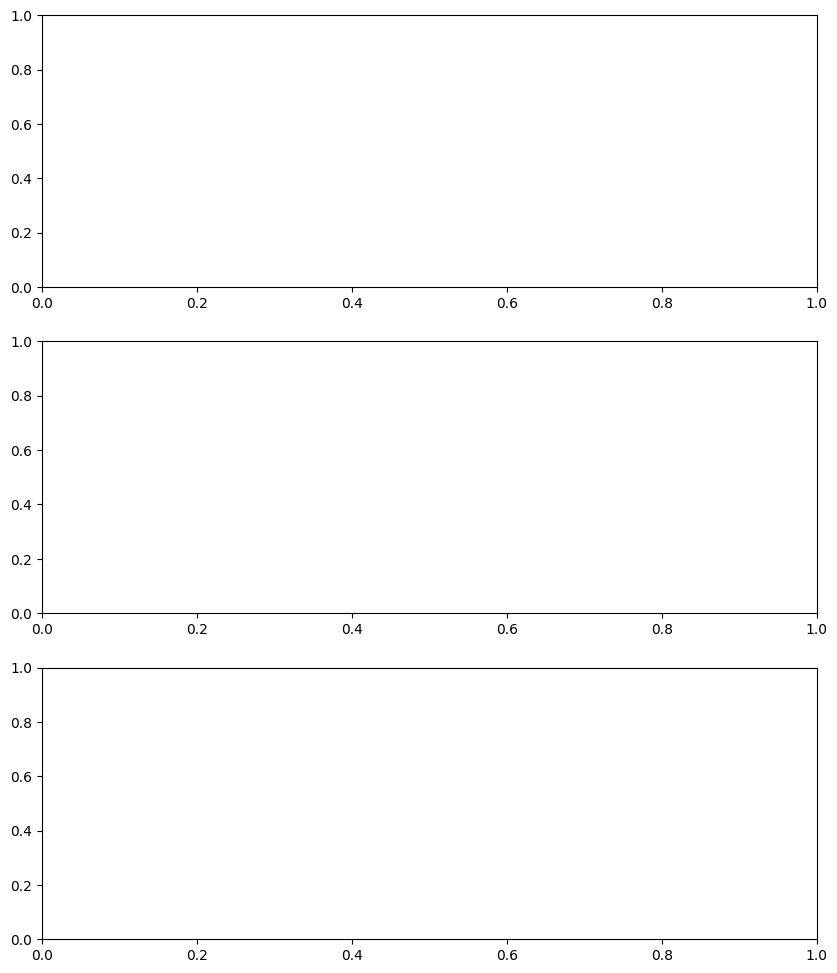

In [9]:
	PARAM = (
    {"min_cluster_size": 20, "min_samples": 5},
    {"min_cluster_size": 20, "min_samples": 3},
    {"min_cluster_size": 20, "min_samples": 25},
)
fig, axes = plt.subplots(3, 1, figsize=(10, 12))
for i, param in enumerate(PARAM):
    hdb = hdbscan.HDBSCAN(**param).fit(X)
    plot(X, hdb.labels_, hdb.probabilities_, param, ax=axes[i])

In [10]:
PARAM = (
    {"cut_distance": 0.1},
    {"cut_distance": 0.5},
    {"cut_distance": 1.0},
)
hdb = hdbscan.HDBSCAN().fit(X)
fig, axes = plt.subplots(len(PARAM), 1, figsize=(10, 12))
for i, param in enumerate(PARAM):
    labels = hdb.dbscan_clustering(**param)
    plot(X, labels, hdb.probabilities_, param, ax=axes[i])

NameError: name 'hdbscan' is not defined

In [11]:
from sklearn.metrics import silhouette_score

# Compute Silhouette Score for HDBSCAN clustering results
sil_score = silhouette_score(X, hdb.labels_)
print(f"Silhouette Score: {sil_score}")

Silhouette Score: 0.5107810559265409


In [12]:
from sklearn.metrics import davies_bouldin_score

# Compute Davies-Bouldin Index for HDBSCAN clustering results
dbi_score = davies_bouldin_score(X, hdb.labels_)
print(f"Davies-Bouldin Index: {dbi_score}")

Davies-Bouldin Index: 1.6189633070762262


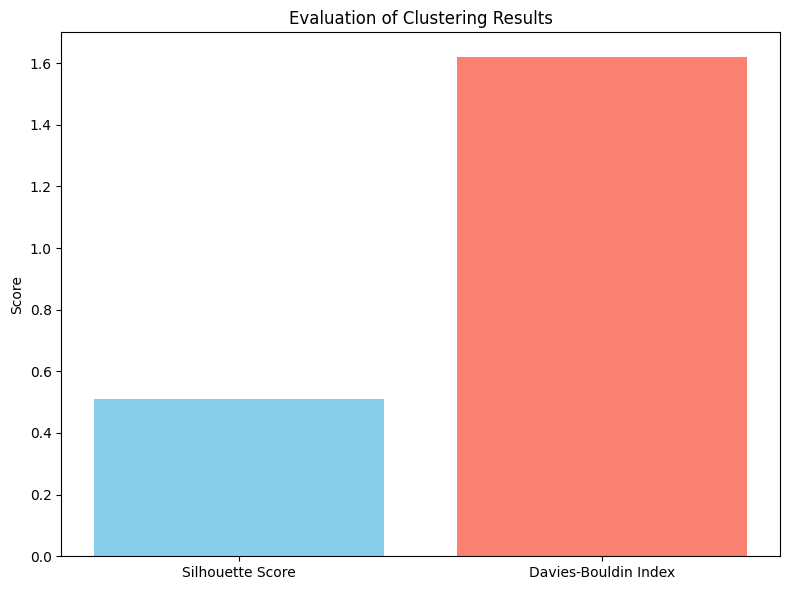

In [13]:
scores = {
    "Silhouette Score": sil_score,
    "Davies-Bouldin Index": dbi_score
}

# Plot the evaluation results
fig, ax = plt.subplots(figsize=(8, 6))
ax.bar(scores.keys(), scores.values(), color=['skyblue', 'salmon'])
ax.set_title("Evaluation of Clustering Results")
ax.set_ylabel("Score")
plt.tight_layout()
plt.show()